### multiple linear reagration 

In [ ]:
### import required 
 

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 


In [38]:
df=pd.read_csv("50_Startups.csv")
df.head()

,RnD,Administration,Marketing,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   RnD             50 non-null     float64
 1   Administration  50 non-null     float64
 2   Marketing       50 non-null     float64
 3   State           50 non-null     object 
 4   Profit          50 non-null     float64
dtypes: float64(4), object(1)
memory usage: 2.1+ KB


In [40]:
df.describe()

,RnD,Administration,Marketing,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


In [41]:
from sk learn.preprocessing import LabelEncoder

encoder=LabelEncoder()

df['State']=encoder.fit_transform(df['State'])


In [42]:
encoder.classes_

array(['California', 'Florida', 'New York'], dtype=object)

In [43]:
df.corr()

,RnD,Administration,Marketing,State,Profit
RnD,1.000000,0.241955,0.724248,0.104685,0.972900
Administration,0.241955,1.000000,-0.032154,0.011847,0.200717
Marketing,0.724248,-0.032154,1.000000,0.077670,0.747766
State,0.104685,0.011847,0.077670,1.000000,0.101796
Profit,0.972900,0.200717,0.747766,0.101796,1.000000


<Axes: >

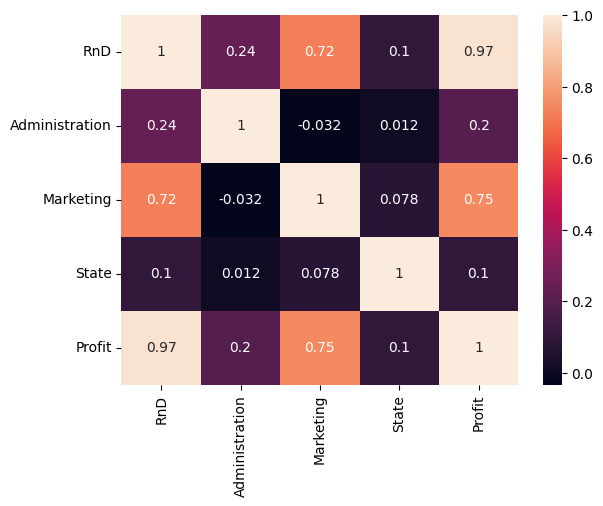

In [44]:
sns.heatmap(df.corr(),annot=True)

In [47]:
X=df.drop(['Administration','State','Profit'],axis=1)
y=df['Profit']

In [48]:
X.columns

Index(['RnD', 'Marketing'], dtype='object')

In [49]:
from sklearn.model_selection import train_test_split
X_train, X_test,y_train,y_test=train_test_split(
    X,y,train_size=0.7,random_state=42)

In [50]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

In [51]:
C

In [52]:
from sklearn.metrics import mean_absolute_error
mae=mean_absolute_error(y_test,y_pred)
print(f"mean absoluteerror={mae:.2f}")

mean absoluteerror=6449.24


In [53]:
from sklearn.metrics import mean_absolute_percentage_error
mape=mean_absolute_percentage_error(y_test,y_pred)
print(f"mean absolute percentage error={mape:.2f}")

mean absolute percentage error=0.07


In [54]:
from sklearn.metrics import mean_squared_error
mse=mean_squared_error(y_test,y_pred)
print(f"ean_squared_erro={mae:.2f}")

ean_squared_erro=6449.24


In [55]:
from sklearn.metrics import r2_score
r2=r2_score(y_test,y_pred)
print(f"r2={r2:.2f}")

r2=0.95


In [56]:
n=y_test.size
p=2
adjusted_r2=1-((1-r2)*((n-1)/(n-p-1)))
print(f"adjested r2={adjusted_r2:.2f}")

adjested r2=0.94


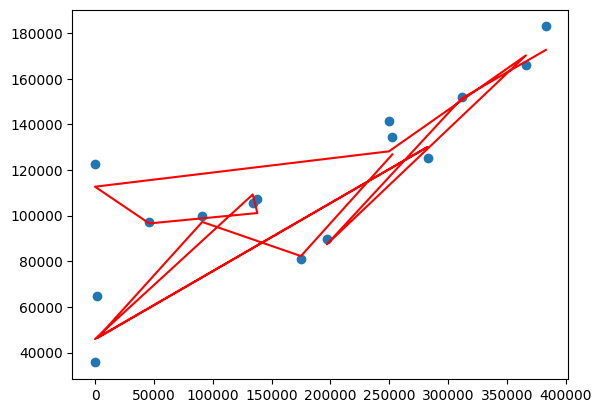

In [57]:
plt.scatter(X_test['Marketing'],y_test)
plt.plot(X_test['Marketing'],y_pred,color="red")

In [58]:
# sience the model is trained with 2 independat variable and chart is using the only one of them 

### persist the model

In [59]:
import pickle
with open("startup_model1.pkl","wb") as file:
    pickle.dump(model,file)